# TED TALK RECOMMENDATION SYSTEM USING MACHINE LEARNING

## Imports & Data Ingestion

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
file_path = "ted_talks.csv"
df = pd.read_csv(file_path)
print("Dataset loaded successfully!")

Dataset loaded successfully!


## Structural Data Inspection

In [3]:
print("=== SHAPE ===")
print(f"Rows: {df.shape[0]} | Columns: {df.shape[1]}\n")
print("=== DATASET INFO ===")
df.info()
print("\n=== MISSING VALUES COUNT ===")
print(df.isnull().sum())
print("\n=== DUPLICATE ROWS COUNT ===")
print(f"Duplicates: {df.duplicated().sum()}")

=== SHAPE ===
Rows: 5430 | Columns: 27

=== DATASET INFO ===
<class 'pandas.DataFrame'>
RangeIndex: 5430 entries, 0 to 5429
Data columns (total 27 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   id                                   5430 non-null   int64  
 1   socialTitle                          5430 non-null   str    
 2   description                          5430 non-null   str    
 3   canonicalUrl                         5430 non-null   str    
 4   curatorApproved                      5430 non-null   bool   
 5   audioDownload                        3069 non-null   str    
 6   duration                             5430 non-null   int64  
 7   audioInternalLanguageCode            5430 non-null   str    
 8   featured                             5430 non-null   bool   
 9   hasTranslations                      5430 non-null   bool   
 10  publishedAt                          5430 non-

## Shortlist Selected Variables & Descriptions

In [4]:
shortlisted_cols = [
    'socialTitle', 'description', 'duration', 'publishedAt', 
    'videoContext', 'viewedCount', 'relatedVideos', 'topics', 
    'type', 'speakers'
]
df_clean = df[[col for col in shortlisted_cols if col in df.columns]].copy()
print("SELECTED VARIABLES & DESCRIPTIONS")
print("""
1. socialTitle (Text Metadata):
   - Role: Display / NLP Feature
   - Purpose: Talk title used for UI recommendation display and NLP feature derivation (title length, sentiment).
   
2. description (Text Metadata):
   - Role: Recommendation Feature / Content Filtering
   - Purpose: Rich text summary used for TF-IDF / Content-Based Similarity matching between talks.
   
3. duration (Numerical Feature):
   - Role: Predictive Feature
   - Purpose: Talk length in seconds; tests whether shorter or longer talks generate higher engagement.
   
4. publishedAt (Temporal Feature):
   - Role: Predictive Feature / Recency Weighting
   - Purpose: Extract published year/month to account for talk age and trend analysis over time.
   
5. videoContext (Categorical Feature):
   - Role: Categorical Feature / Metadata Display
   - Purpose: TED event context (e.g., TED2020, TEDx); captures event prestige and branding impact.
   
6. topics (Categorical / Tag Feature):
   - Role: Recommendation Feature / Content Filtering
   - Purpose: List of category tags used for topic-based similarity matching and topic counts.
   
7. type (Categorical Metadata):
   - Role: Content Filter
   - Purpose: Distinguishes standard TED Talks from interviews, performances, or podcasts.
   
8. speakers (Categorical / Entity Feature):
   - Role: Recommendation Feature / Metadata Display
   - Purpose: Presenter details used for speaker-based filtering and authority signals.
   
9. relatedVideos (Network Graph Feature):
   - Role: Recommendation Feature
   - Purpose: Built-in TED recommendation graph links used to evaluate default item-to-item similarity.
   
10. viewedCount (NUMERICAL TARGET VARIABLE):
   - Role: Target Variable (Y)
   - Purpose: Total view count measuring talk popularity and engagement classification (High vs. Low).
""")
print("\nSHORTLISTED DATASET PREVIEW")
display(df_clean.head())

SELECTED VARIABLES & DESCRIPTIONS

1. socialTitle (Text Metadata):
   - Role: Display / NLP Feature
   - Purpose: Talk title used for UI recommendation display and NLP feature derivation (title length, sentiment).

2. description (Text Metadata):
   - Role: Recommendation Feature / Content Filtering
   - Purpose: Rich text summary used for TF-IDF / Content-Based Similarity matching between talks.

3. duration (Numerical Feature):
   - Role: Predictive Feature
   - Purpose: Talk length in seconds; tests whether shorter or longer talks generate higher engagement.

4. publishedAt (Temporal Feature):
   - Role: Predictive Feature / Recency Weighting
   - Purpose: Extract published year/month to account for talk age and trend analysis over time.

5. videoContext (Categorical Feature):
   - Role: Categorical Feature / Metadata Display
   - Purpose: TED event context (e.g., TED2020, TEDx); captures event prestige and branding impact.

6. topics (Categorical / Tag Feature):
   - Role: Recommen

,socialTitle,description,duration,publishedAt,videoContext,viewedCount,relatedVideos,topics,type,speakers
0,How do jetpacks work? And why don't we all hav...,"In 1961, Yuri Gagarin piloted a spacecraft in ...",0,2022-02-10T16:02:44+00:00,TED-Ed,658,"[{'id': '38337'}, {'id': '75175'}, {'id': '636...","[{'id': '52', 'name': 'education', 'slug': 'ed...","{'id': '3', 'name': 'TED-Ed Original'}","[{'firstName': 'Richard', 'middleName': '', 'l..."
1,What regret can teach you about living a good ...,Regret is one of our most powerful emotions --...,1379,2022-02-10T15:49:39+00:00,TED Membership,239182,"[{'id': '618'}, {'id': '81681'}, {'id': '84765...","[{'id': '86', 'name': 'communication', 'slug':...","{'id': '6', 'name': 'Original Content'}","[{'firstName': 'Daniel H.', 'middleName': '', ..."
2,"How to fix the ""bugs"" in the net-zero code","Lucas Joppa, Microsoft's first chief environme...",626,2022-02-09T15:38:55+00:00,Countdown Summit,329457,"[{'id': '81388'}, {'id': '74405'}, {'id': '837...","[{'id': '5', 'name': 'environment', 'slug': 'e...","{'id': '1', 'name': 'TED Stage Talk'}","[{'firstName': 'Lucas', 'middleName': '', 'las..."
3,"""Big Yellow Taxi"" / ""Song for Sunshine""",Legendary Scottish indie-pop band Belle and Se...,551,2022-02-09T15:27:54+00:00,Countdown Summit,401,"[{'id': '86535'}, {'id': '86287'}, {'id': '852...","[{'id': '40', 'name': 'music', 'slug': 'music'...","{'id': '1', 'name': 'TED Stage Talk'}","[{'firstName': '', 'middleName': '', 'lastName..."
4,How film created hope after the Beirut port ex...,When Lebanon was rocked by a massive explosion...,751,2022-02-08T20:48:27+00:00,TEDWomen 2021,176062,"[{'id': '76221'}, {'id': '81389'}, {'id': '762...","[{'id': '68', 'name': 'creativity', 'slug': 'c...","{'id': '1', 'name': 'TED Stage Talk'}","[{'firstName': 'Mounia', 'middleName': '', 'la..."


## Multi-Variable Correlation Matrix & Heatmap

CORRELATION MATRIX


,socialTitle,description,duration,publishedAt,videoContext,viewedCount,relatedVideos,topics,type,speakers
socialTitle,1.00,-0.00,0.00,0.03,0.02,0.05,-0.02,-0.01,0.03,0.01
description,-0.00,1.00,-0.02,0.03,0.02,0.02,-0.01,-0.02,0.04,0.06
duration,0.00,-0.02,1.00,-0.18,0.10,0.03,-0.00,-0.04,-0.03,0.02
publishedAt,0.03,0.03,-0.18,1.00,-0.00,-0.11,0.23,0.09,0.40,-0.05
videoContext,0.02,0.02,0.10,-0.00,1.00,-0.04,-0.08,-0.07,-0.04,0.00
viewedCount,0.05,0.02,0.03,-0.11,-0.04,1.00,-0.07,-0.03,-0.09,-0.01
relatedVideos,-0.02,-0.01,-0.00,0.23,-0.08,-0.07,1.00,0.02,0.12,-0.02
topics,-0.01,-0.02,-0.04,0.09,-0.07,-0.03,0.02,1.00,-0.04,-0.01
type,0.03,0.04,-0.03,0.40,-0.04,-0.09,0.12,-0.04,1.00,-0.00
speakers,0.01,0.06,0.02,-0.05,0.00,-0.01,-0.02,-0.01,-0.00,1.00


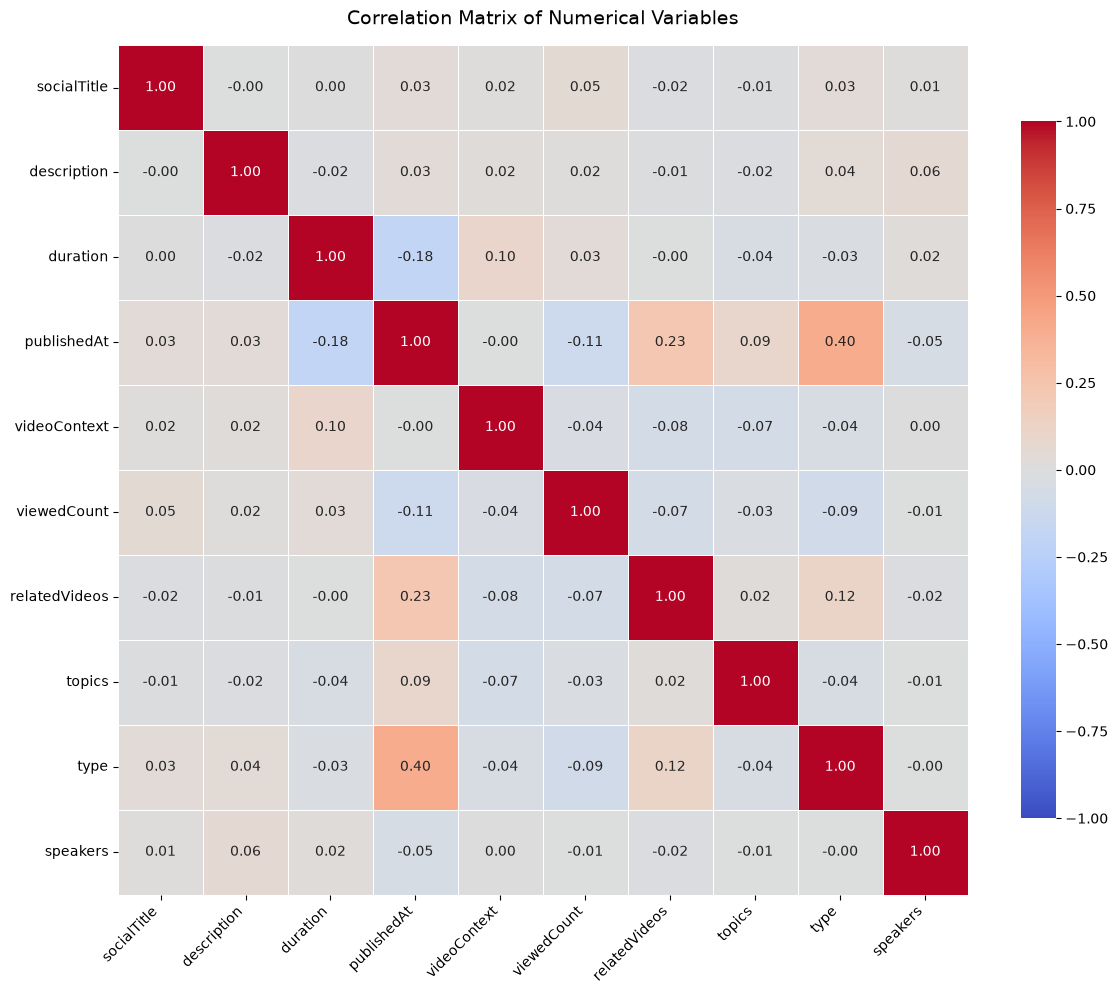

In [5]:
corr_df = pd.DataFrame()
for col in df_clean.columns:
    if pd.api.types.is_numeric_dtype(df_clean[col]):
        corr_df[col] = df_clean[col]
    elif pd.api.types.is_datetime64_any_dtype(df_clean[col]):
        corr_df[col] = df_clean[col].astype('int64') // 10**9  
    else:
        corr_df[col] = df_clean[col].astype(str).astype('category').cat.codes
corr_matrix = corr_df.corr()
print("CORRELATION MATRIX")
display(corr_matrix.round(2))
plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5, square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation Matrix of Numerical Variables", fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)
plt.tight_layout()
plt.show()

## Missing Values, Schema Info, and Statistical Summary

In [6]:
print("1. DATASET INFO (SHORTLISTED COLUMNS)")
df_clean.info()
print("\n2. MISSING VALUES COUNT")
missing_counts = df_clean.isnull().sum()
missing_percent = (missing_counts / len(df_clean)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing_counts,
    'Percentage (%)': missing_percent.round(2)
})
display(missing_df)
print("\n3. DESCRIPTIVE STATISTICS (NUMERICAL)")
display(df_clean.describe())
print("\n4. DESCRIPTIVE STATISTICS (CATEGORICAL/TEXT)")
display(df_clean.describe(include=['object']))

1. DATASET INFO (SHORTLISTED COLUMNS)
<class 'pandas.DataFrame'>
RangeIndex: 5430 entries, 0 to 5429
Data columns (total 10 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   socialTitle    5430 non-null   str  
 1   description    5430 non-null   str  
 2   duration       5430 non-null   int64
 3   publishedAt    5430 non-null   str  
 4   videoContext   5430 non-null   str  
 5   viewedCount    5430 non-null   int64
 6   relatedVideos  5430 non-null   str  
 7   topics         5430 non-null   str  
 8   type           5430 non-null   str  
 9   speakers       5430 non-null   str  
dtypes: int64(2), str(8)
memory usage: 424.3 KB

2. MISSING VALUES COUNT


,Missing Count,Percentage (%)
socialTitle,0,0.0
description,0,0.0
duration,0,0.0
publishedAt,0,0.0
videoContext,0,0.0
viewedCount,0,0.0
relatedVideos,0,0.0
topics,0,0.0
type,0,0.0
speakers,0,0.0



3. DESCRIPTIVE STATISTICS (NUMERICAL)


,duration,viewedCount
count,5430.000000,5.430000e+03
mean,716.025414,2.099783e+06
std,523.549272,3.618841e+06
min,0.000000,4.010000e+02
25%,363.000000,6.711732e+05
50%,692.000000,1.362670e+06
75%,942.000000,2.173180e+06
max,20404.000000,7.254702e+07



4. DESCRIPTIVE STATISTICS (CATEGORICAL/TEXT)


C:\Users\itsdi\AppData\Local\Temp\ipykernel_13380\1581798376.py:14: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df_clean.describe(include=['object']))


,socialTitle,description,publishedAt,videoContext,relatedVideos,topics,type,speakers
count,5430,5430,5430,5430,5430,5430,5430,5430
unique,5429,5429,5371,616,5425,5300,9,4460
top,Biomimicry's surprising lessons from nature's ...,In this inspiring talk about recent developmen...,2007-04-05T00:11:00+00:00,TED-Ed,[],"[{'id': '40', 'name': 'music', 'slug': 'music'...","{'id': '1', 'name': 'TED Stage Talk'}","[{'firstName': 'Alex', 'middleName': '', 'last..."
freq,2,2,20,817,4,27,2825,47


## EDA Visualizations

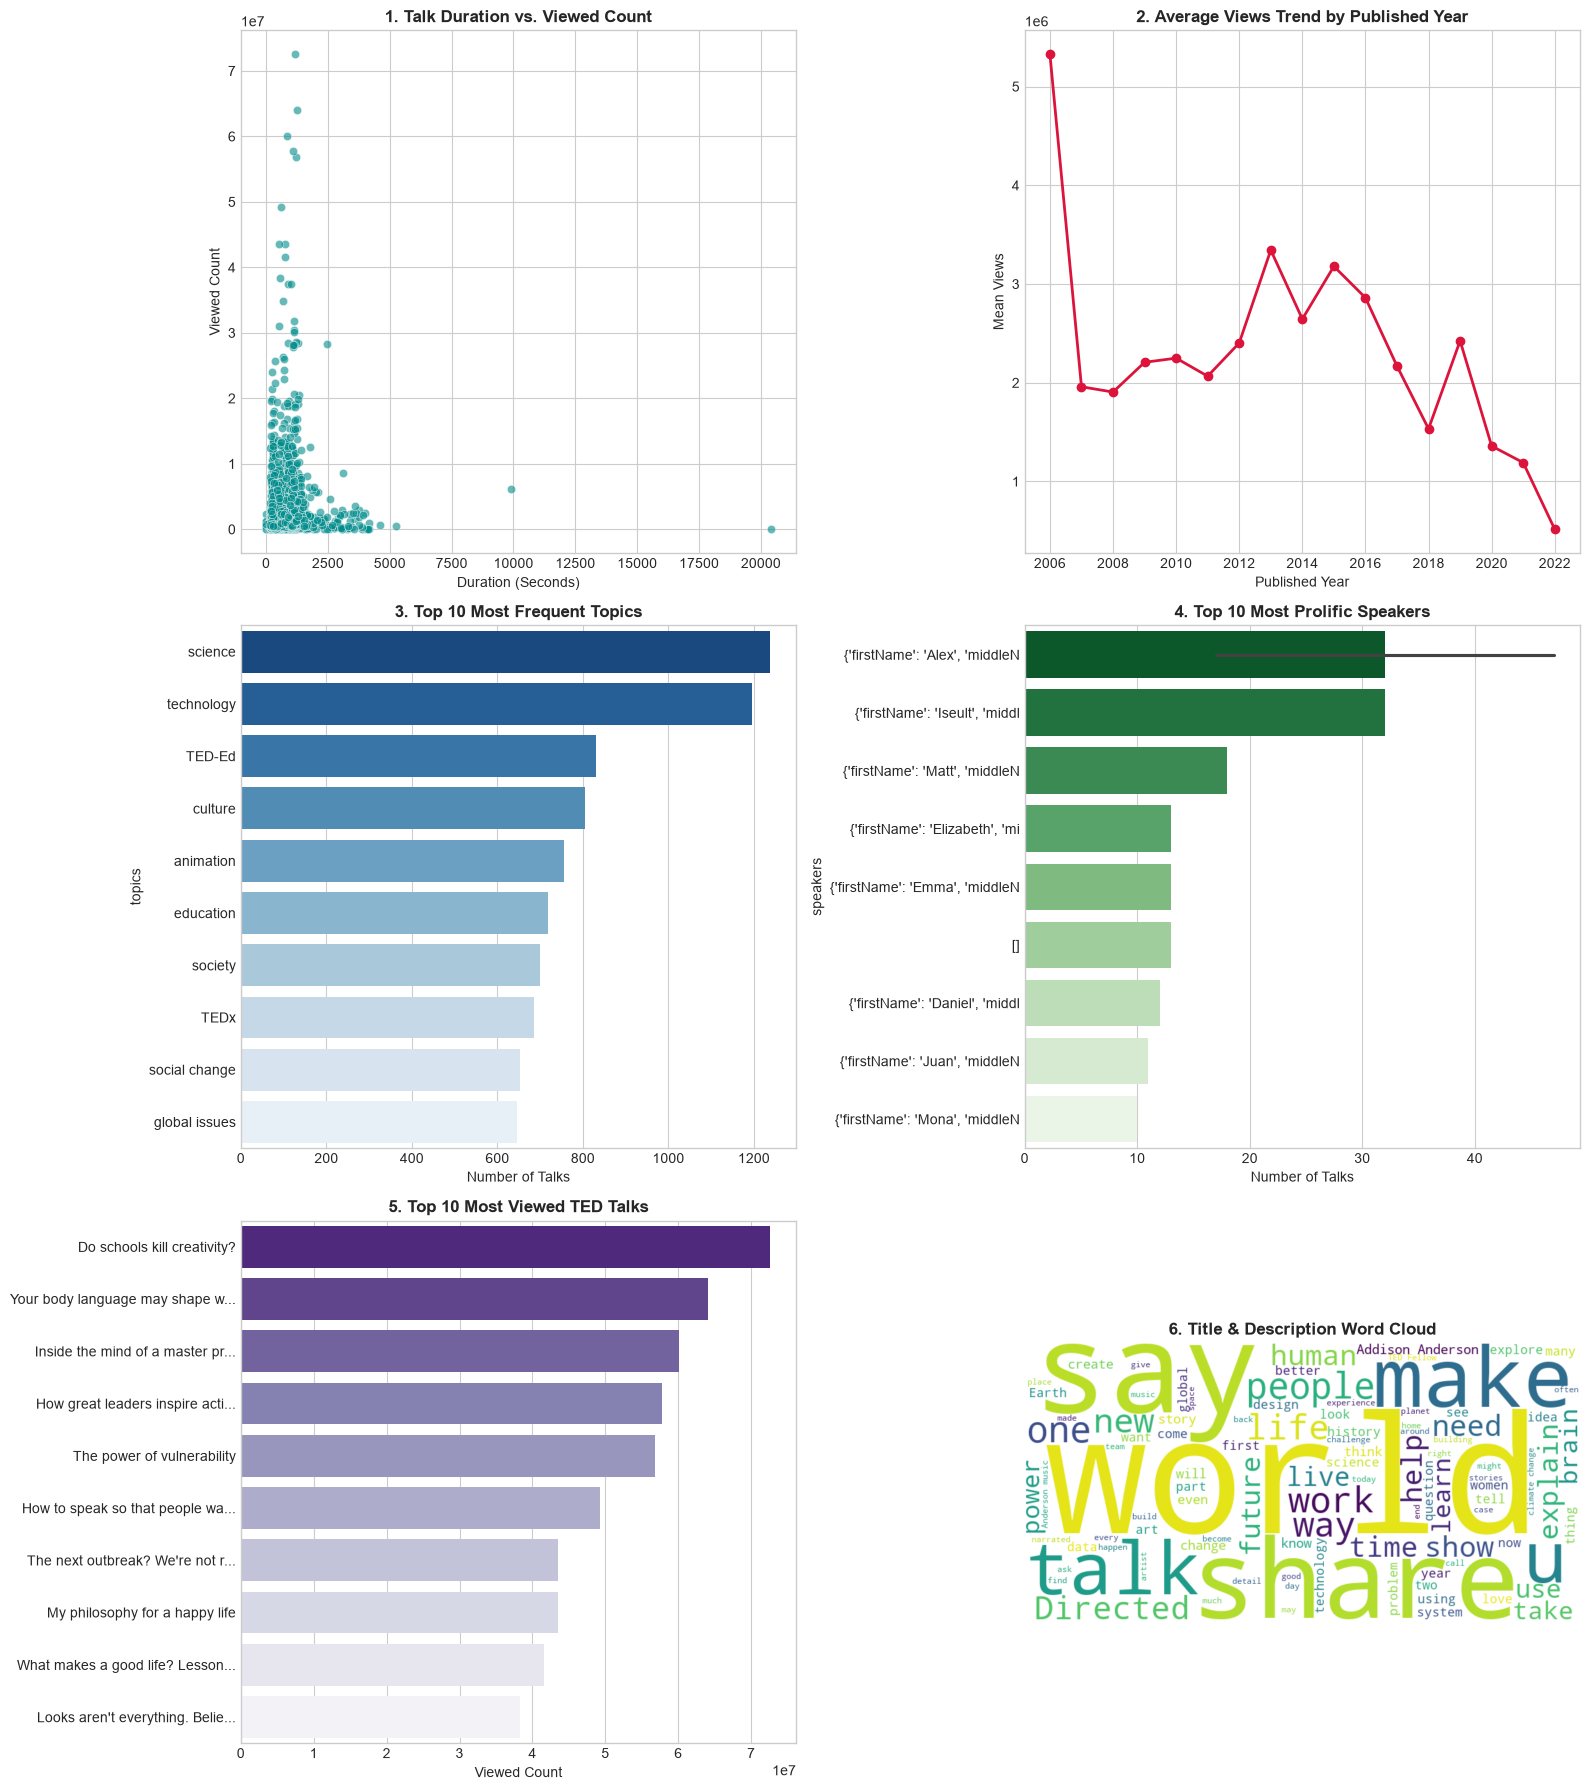

In [7]:
from wordcloud import WordCloud
import ast

df_clean['published_year'] = pd.to_datetime(df_clean['publishedAt'], errors='coerce').dt.year
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
fig = plt.figure(figsize=(16, 18))
plt.subplot(3, 2, 1)
sns.scatterplot(data=df_clean, x='duration', y='viewedCount', color='darkcyan', alpha=0.6)
plt.title('1. Talk Duration vs. Viewed Count', fontsize=12, fontweight='bold')
plt.xlabel('Duration (Seconds)')
plt.ylabel('Viewed Count')

plt.subplot(3, 2, 2)
yearly_views = df_clean.groupby('published_year')['viewedCount'].mean()
plt.plot(yearly_views.index, yearly_views.values, marker='o', color='crimson', linewidth=2)
plt.title('2. Average Views Trend by Published Year', fontsize=12, fontweight='bold')
plt.xlabel('Published Year')
plt.ylabel('Mean Views')

plt.subplot(3, 2, 3)
def parse_topics_list(val):
    if pd.isna(val): return []
    if isinstance(val, str):
        try:
            val = ast.literal_eval(val)
        except:
            val = [x.strip() for x in val.split(',')]
    if isinstance(val, list):
        clean_topics = []
        for item in val:
            if isinstance(item, dict):
                clean_topics.append(item.get('name', item.get('id', str(item))))
            elif isinstance(item, str):
                clean_topics.append(item.strip())
        return clean_topics
    return []
all_topics = df_clean['topics'].apply(parse_topics_list).explode().dropna()
top_10_topics = all_topics.value_counts().head(10)
top_10_topics.index = top_10_topics.index.astype(str).str[:30]
sns.barplot(x=top_10_topics.values, y=top_10_topics.index, hue=top_10_topics.index, legend=False, palette='Blues_r')
plt.title('3. Top 10 Most Frequent Topics', fontsize=12, fontweight='bold')
plt.xlabel('Number of Talks')

plt.subplot(3, 2, 4)
def parse_speaker_name(val):
    if pd.isna(val): return 'Unknown'
    if isinstance(val, str):
        try:
            parsed = ast.literal_eval(val)
            if isinstance(parsed, list) and len(parsed) > 0:
                item = parsed[0]
                return item.get('name', item.get('speaker', str(item))) if isinstance(item, dict) else str(item)
            elif isinstance(parsed, dict):
                return parsed.get('name', str(parsed))
        except:
            pass
    return str(val)
speaker_names = df_clean['speakers'].apply(parse_speaker_name)
top_10_speakers = speaker_names.value_counts().head(10)
top_10_speakers.index = top_10_speakers.index.astype(str).str[:30]
sns.barplot(x=top_10_speakers.values, y=top_10_speakers.index, hue=top_10_speakers.index, legend=False, palette='Greens_r')
plt.title('4. Top 10 Most Prolific Speakers', fontsize=12, fontweight='bold')
plt.xlabel('Number of Talks')

plt.subplot(3, 2, 5)
top_viewed = df_clean.nlargest(10, 'viewedCount').copy()
top_viewed['display_title'] = top_viewed['socialTitle'].astype(str).apply(lambda x: x[:30] + '...' if len(x) > 30 else x)
sns.barplot(data=top_viewed, x='viewedCount', y='display_title', hue='display_title', legend=False, palette='Purples_r')
plt.title('5. Top 10 Most Viewed TED Talks', fontsize=12, fontweight='bold')
plt.xlabel('Viewed Count')
plt.ylabel('')

plt.subplot(3, 2, 6)
combined_text = (df_clean['socialTitle'].fillna('').astype(str).str.cat(df_clean['description'].fillna('').astype(str), sep=' '))
text_data = ' '.join(combined_text)
wordcloud = WordCloud(width=800, height=400, background_color='white', colormap='viridis', max_words=100).generate(text_data)
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('6. Title & Description Word Cloud', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## Data Cleaning, Parsing & Feature Engineering

In [8]:
import ast

df_clean = df.drop_duplicates(subset=['socialTitle', 'description']).copy()
print(f"Shape after deduplication: {df_clean.shape} (1 duplicate removed)")

def parse_topics(val):
    try:
        data = ast.literal_eval(val) if isinstance(val, str) else val
        if isinstance(data, list):
            return [item['name'] for item in data if isinstance(item, dict) and 'name' in item]
    except Exception:
        pass
    return []
def parse_speaker(val):
    try:
        data = ast.literal_eval(val) if isinstance(val, str) else val
        if isinstance(data, list) and len(data) > 0:
            sp = data[0]
            name = f"{sp.get('firstName', '')} {sp.get('lastName', '')}".strip()
            return name if name else 'Unknown Speaker'
    except Exception:
        pass
    return 'Unknown Speaker'
def parse_type(val):
    try:
        data = ast.literal_eval(val) if isinstance(val, str) else val
        if isinstance(data, dict):
            return data.get('name', 'TED Stage Talk')
    except Exception:
        pass
    return 'TED Stage Talk'
df_clean['topic_list'] = df_clean['topics'].apply(parse_topics)
df_clean['topic_tags'] = df_clean['topic_list'].apply(lambda x: ', '.join(x))
df_clean['topic_count'] = df_clean['topic_list'].apply(len)
df_clean['speaker_name'] = df_clean['speakers'].apply(parse_speaker)
df_clean['talk_type'] = df_clean['type'].apply(parse_type)

df_clean['publishedAt_dt'] = pd.to_datetime(df_clean['publishedAt'], errors='coerce')
ref_date = df_clean['publishedAt_dt'].max()
df_clean['published_year'] = df_clean['publishedAt_dt'].dt.year.fillna(2015).astype(int)
df_clean['published_month'] = df_clean['publishedAt_dt'].dt.month.fillna(1).astype(int)
df_clean['published_dayofweek'] = df_clean['publishedAt_dt'].dt.dayofweek.fillna(0).astype(int)
df_clean['talk_age_days'] = (ref_date - df_clean['publishedAt_dt']).dt.days.fillna(0).astype(int)

df_clean['duration_mins'] = (df_clean['duration'] / 60.0).round(2)
df_clean['title_word_count'] = df_clean['socialTitle'].fillna('').apply(lambda x: len(str(x).split()))
df_clean['desc_word_count'] = df_clean['description'].fillna('').apply(lambda x: len(str(x).split()))

top_contexts = df_clean['videoContext'].value_counts().nlargest(8).index.tolist()
df_clean['event_category'] = df_clean['videoContext'].apply(lambda x: x if x in top_contexts else 'Other')
print("Engineered Feature Preview:")
display(df_clean[['socialTitle', 'speaker_name', 'topic_tags', 'duration_mins', 'talk_age_days', 'event_category', 'talk_type']].head(5))

Shape after deduplication: (5429, 27) (1 duplicate removed)
Engineered Feature Preview:


,socialTitle,speaker_name,topic_tags,duration_mins,talk_age_days,event_category,talk_type
0,How do jetpacks work? And why don't we all hav...,Richard Browning,"education, TED-Ed, animation, design, technolo...",0.00,0,TED-Ed,TED-Ed Original
1,What regret can teach you about living a good ...,Daniel H. Pink,"communication, emotions, psychology, relations...",22.98,0,Other,Original Content
2,"How to fix the ""bugs"" in the net-zero code",Lucas Joppa,"environment, software, climate change, Countdo...",10.43,1,Other,TED Stage Talk
3,"""Big Yellow Taxi"" / ""Song for Sunshine""",Belle and Sebastian,"music, Countdown, performance",9.18,1,Other,TED Stage Talk
4,How film created hope after the Beirut port ex...,Mounia Akl,"creativity, art, Middle East, film, storytelling",12.52,1,Other,TED Stage Talk


## Target Variable Formulation & Target Leakage Prevention

In [9]:
median_views = df_clean['viewedCount'].median()
df_clean['is_popular'] = (df_clean['viewedCount'] >= median_views).astype(int)

print(f"=== POPULARITY THRESHOLD ===")
print(f"Median Historical View Count: {median_views:,.0f} views")
print("\nTarget Class Distribution:")
print(df_clean['is_popular'].value_counts())
print(f"\nClass Balance: High Popularity = {df_clean['is_popular'].mean()*100:.1f}%, Low Popularity = {(1 - df_clean['is_popular'].mean())*100:.1f}%")

num_features = ['duration_mins', 'talk_age_days', 'published_year', 'published_month', 'published_dayofweek', 'topic_count', 'title_word_count', 'desc_word_count']
cat_features = ['event_category', 'talk_type']

X = df_clean[num_features + cat_features]
y = df_clean['is_popular']

print(f"\nPredictor Matrix X Shape: {X.shape}")
print(f"Features: {list(X.columns)}")

=== POPULARITY THRESHOLD ===
Median Historical View Count: 1,362,484 views

Target Class Distribution:
is_popular
1    2715
0    2714
Name: count, dtype: int64

Class Balance: High Popularity = 50.0%, Low Popularity = 50.0%

Predictor Matrix X Shape: (5429, 10)
Features: ['duration_mins', 'talk_age_days', 'published_year', 'published_month', 'published_dayofweek', 'topic_count', 'title_word_count', 'desc_word_count', 'event_category', 'talk_type']


## Supervised Classification Modeling & Hyperparameter Tuning

To predict whether a TED talk achieves high popularity (>= 1,362,484 views, the dataset median), we implement and benchmark three supervised classification architectures:
1. **Logistic Regression**: Linear probabilistic baseline with L2 regularization.
2. **Decision Tree Classifier**: Non-linear hierarchical decision tree with tree-pruning constraints.
3. **Random Forest Classifier**: Ensemble bagging model aggregating decorrelated decision trees.

### Methodology:
- **Phase 1: Baseline Modeling**: All three models are trained with default hyperparameters to establish initial performance benchmarks.
- **Phase 2: Systematic Hyperparameter Tuning**: 5-Fold Stratified `GridSearchCV` scoring on `roc_auc` is performed to find the optimal regularization, tree depth, and ensemble parameters.
- **Phase 3: Comparative Evaluation**: Baseline vs. Tuned metrics (Accuracy, Precision, Recall, F1-Score, ROC-AUC) are displayed side-by-side to quantify the gains achieved through hyperparameter optimization.


In [10]:
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_features), 
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_features)
])

print("--- Phase 1: Training Baseline Models (Default Parameters) ---")
lr_base = Pipeline([('prep', preprocessor), ('clf', LogisticRegression(random_state=42))])
lr_base.fit(X_train, y_train)
dt_base = Pipeline([('prep', preprocessor), ('clf', DecisionTreeClassifier(random_state=42))])
dt_base.fit(X_train, y_train)
rf_base = Pipeline([('prep', preprocessor), ('clf', RandomForestClassifier(random_state=42))])
rf_base.fit(X_train, y_train)

base_models = {
    'Logistic Regression (Baseline)': lr_base,
    'Decision Tree (Baseline)': dt_base,
    'Random Forest (Baseline)': rf_base
}

base_rows = []
for m_name, pipe in base_models.items():
    preds = pipe.predict(X_test)
    probs = pipe.predict_proba(X_test)[:, 1]
    base_rows.append({
        'Model': m_name,
        'Accuracy': round(accuracy_score(y_test, preds), 4),
        'Precision': round(precision_score(y_test, preds), 4),
        'Recall': round(recall_score(y_test, preds), 4),
        'F1-Score': round(f1_score(y_test, preds), 4),
        'ROC-AUC': round(roc_auc_score(y_test, probs), 4)
    })

base_df = pd.DataFrame(base_rows)
print("\n=== BASELINE MODEL PERFORMANCE BENCHMARK ===")
display(base_df)

print("\n--- Phase 2: Hyperparameter Tuning via 5-Fold Stratified GridSearchCV ---")
lr_param_grid = {
    'clf__C': [0.01, 0.1, 1.0, 10.0],
    'clf__solver': ['lbfgs', 'liblinear'],
    'clf__max_iter': [200, 500]
}
dt_param_grid = {
    'clf__max_depth': [4, 6, 8, 10],
    'clf__min_samples_leaf': [10, 20, 50],
    'clf__criterion': ['gini', 'entropy']
}
rf_param_grid = {
    'clf__n_estimators': [100, 150, 200],
    'clf__max_depth': [8, 12, 16],
    'clf__min_samples_leaf': [2, 5, 10],
    'clf__max_features': ['sqrt']
}

print("Tuning Logistic Regression...")
lr_grid = GridSearchCV(Pipeline([('prep', preprocessor), ('clf', LogisticRegression(random_state=42))]), lr_param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
lr_grid.fit(X_train, y_train)
lr_pipe = lr_grid.best_estimator_
print(f"Optimal Logistic Regression Parameters: {lr_grid.best_params_}")

print("Tuning Decision Tree...")
dt_grid = GridSearchCV(Pipeline([('prep', preprocessor), ('clf', DecisionTreeClassifier(random_state=42))]), dt_param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
dt_grid.fit(X_train, y_train)
dt_pipe = dt_grid.best_estimator_
print(f"Optimal Decision Tree Parameters: {dt_grid.best_params_}")

print("Tuning Random Forest...")
rf_grid = GridSearchCV(Pipeline([('prep', preprocessor), ('clf', RandomForestClassifier(random_state=42))]), rf_param_grid, cv=5, scoring='roc_auc', n_jobs=-1)
rf_grid.fit(X_train, y_train)
rf_pipe = rf_grid.best_estimator_
print(f"Optimal Random Forest Parameters: {rf_grid.best_params_}")

lr_preds = lr_pipe.predict(X_test)
lr_probs = lr_pipe.predict_proba(X_test)[:, 1]
dt_preds = dt_pipe.predict(X_test)
dt_probs = dt_pipe.predict_proba(X_test)[:, 1]
rf_preds = rf_pipe.predict(X_test)
rf_probs = rf_pipe.predict_proba(X_test)[:, 1]
models_dict = {
    'Logistic Regression': (lr_preds, lr_probs),
    'Decision Tree': (dt_preds, dt_probs),
    'Random Forest': (rf_preds, rf_probs)
}

tuned_rows = []
for m_name, (preds, probs) in models_dict.items():
    tuned_rows.append({
        'Model': f"{m_name} (Tuned)",
        'Accuracy': round(accuracy_score(y_test, preds), 4),
        'Precision': round(precision_score(y_test, preds), 4),
        'Recall': round(recall_score(y_test, preds), 4),
        'F1-Score': round(f1_score(y_test, preds), 4),
        'ROC-AUC': round(roc_auc_score(y_test, probs), 4)
    })

tuned_df = pd.DataFrame(tuned_rows)
print("\n=== TUNED MODEL PERFORMANCE BENCHMARK ===")
display(tuned_df)

--- Phase 1: Training Baseline Models (Default Parameters) ---

=== BASELINE MODEL PERFORMANCE BENCHMARK ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression (Baseline),0.5700,0.5671,0.5912,0.5789,0.6067
1,Decision Tree (Baseline),0.6068,0.6070,0.6059,0.6065,0.6068
2,Random Forest (Baseline),0.6952,0.6853,0.7219,0.7031,0.7476



--- Phase 2: Hyperparameter Tuning via 5-Fold Stratified GridSearchCV ---
Tuning Logistic Regression...
Optimal Logistic Regression Parameters: {'clf__C': 10.0, 'clf__max_iter': 200, 'clf__solver': 'liblinear'}
Tuning Decision Tree...
Optimal Decision Tree Parameters: {'clf__criterion': 'entropy', 'clf__max_depth': 10, 'clf__min_samples_leaf': 50}
Tuning Random Forest...
Optimal Random Forest Parameters: {'clf__max_depth': 12, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 2, 'clf__n_estimators': 150}

=== TUNED MODEL PERFORMANCE BENCHMARK ===


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression (Tuned),0.5700,0.5671,0.5912,0.5789,0.6057
1,Decision Tree (Tuned),0.6611,0.6554,0.6796,0.6673,0.7143
2,Random Forest (Tuned),0.6906,0.6711,0.7477,0.7073,0.7505


## Comprehensive Model Diagnostics & Visualizations

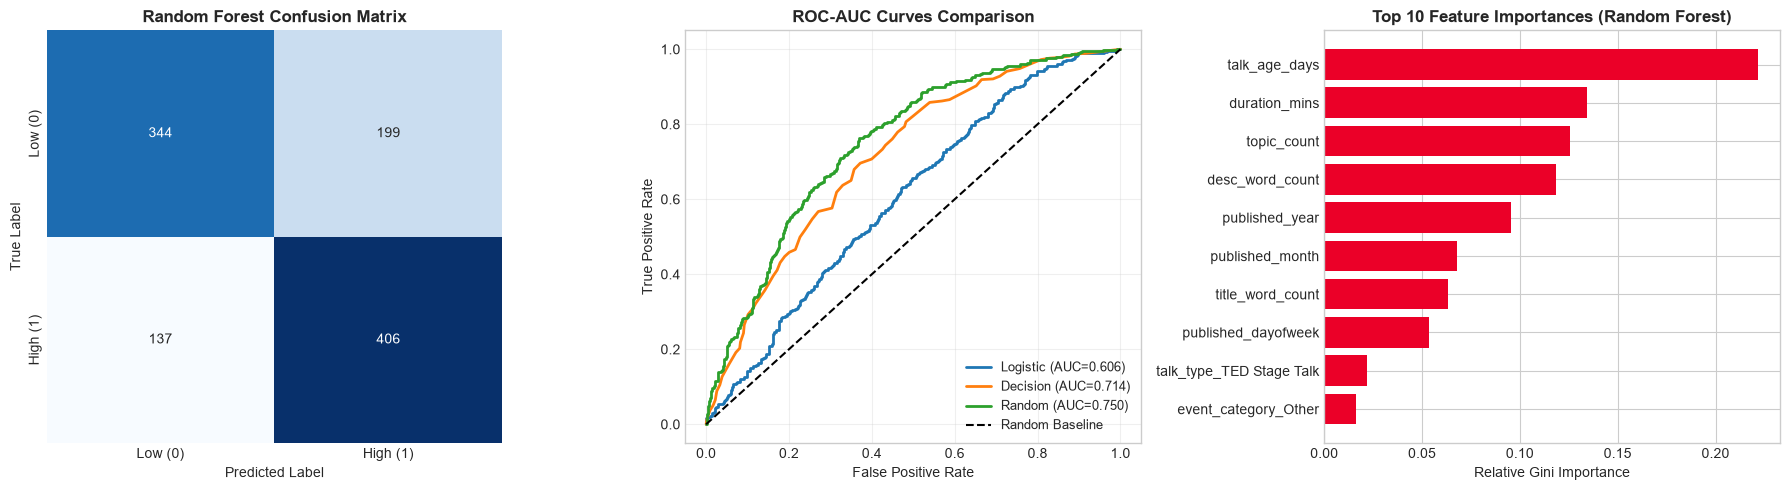

In [11]:
from sklearn.metrics import confusion_matrix, roc_curve
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cm_rf = confusion_matrix(y_test, rf_preds)
sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0], xticklabels=['Low (0)', 'High (1)'], yticklabels=['Low (0)', 'High (1)'])
axes[0].set_title('Random Forest Confusion Matrix', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

for m_name, (_, probs) in models_dict.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    auc_val = roc_auc_score(y_test, probs)
    axes[1].plot(fpr, tpr, lw=2, label=f"{m_name.split()[0]} (AUC={auc_val:.3f})")
axes[1].plot([0, 1], [0, 1], 'k--', lw=1.5, label='Random Baseline')
axes[1].set_title('ROC-AUC Curves Comparison', fontsize=12, fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend(loc='lower right', fontsize=9)
axes[1].grid(alpha=0.3)

rf_model = rf_pipe.named_steps['clf']
cat_encoder = rf_pipe.named_steps['prep'].named_transformers_['cat']
cat_cols = cat_encoder.get_feature_names_out(cat_features).tolist()
all_feature_names = num_features + cat_cols
importances = rf_model.feature_importances_

feat_df = pd.DataFrame({
    'Feature': all_feature_names,
    'Importance': importances
}).sort_values('Importance', ascending=True).tail(10)

axes[2].barh(feat_df['Feature'], feat_df['Importance'], color='#eb0028')
axes[2].set_title('Top 10 Feature Importances (Random Forest)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Relative Gini Importance')

plt.tight_layout()
plt.show()


## Content-Based Recommendation Engine (TF-IDF & Cosine Similarity)

In [12]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

df_clean['combined_content'] = (
    df_clean['socialTitle'].fillna('') + " " + 
    df_clean['description'].fillna('') + " " + 
    df_clean['topic_tags'].fillna('') + " " + 
    df_clean['speaker_name'].fillna('')
)

tfidf = TfidfVectorizer(max_features=5000, stop_words='english', ngram_range=(1, 2))
tfidf_matrix = tfidf.fit_transform(df_clean['combined_content'])
print(f"TF-IDF Matrix Shape: {tfidf_matrix.shape} (5,429 talks, 5,000 features)")

sample_query = "climate change and renewable green energy"
query_vec = tfidf.transform([sample_query])
sample_sims = cosine_similarity(query_vec, tfidf_matrix).flatten()

top_matches = sample_sims.argsort()[::-1][:5]
print(f"\nSample Retrieval for query: '{sample_query}'")
for rank, idx in enumerate(top_matches, 1):
    row = df_clean.iloc[idx]
    print(f"{rank}. {row['socialTitle']} | Speaker: {row['speaker_name']} | Cosine Similarity: {sample_sims[idx]:.4f}")

TF-IDF Matrix Shape: (5429, 5000) (5,429 talks, 5,000 features)

Sample Retrieval for query: 'climate change and renewable green energy'
1. How India could pull off the world's most ambitious energy transition | Speaker: Varun Sivaram | Cosine Similarity: 0.4149
2. Do the green thing | Speaker: Andy Hobsbawm | Cosine Similarity: 0.3935
3. A vision for sustainable energy in Africa | Speaker: Chibeze Ezekiel | Cosine Similarity: 0.3793
4. A 40-year plan for energy | Speaker: Amory Lovins | Cosine Similarity: 0.3663
5. High-altitude wind energy from kites! | Speaker: Saul Griffith | Cosine Similarity: 0.3645


## Two-Stage Recommender Architecture (Semantic Retrieval + 3-Model Popularity Ranking)

In [13]:
class MultiModelTEDRecommender:
    def __init__(self, data_df, tfidf_model, tfidf_mat, lr_model, dt_model, rf_model, feature_cols):
        self.df = data_df.reset_index(drop=True).copy()
        self.tfidf = tfidf_model
        self.tfidf_matrix = tfidf_mat
        self.lr_model = lr_model
        self.dt_model = dt_model
        self.rf_model = rf_model
        self.feature_cols = feature_cols
        
        X_all = self.df[self.feature_cols]
        
        self.df['lr_prob'] = self.lr_model.predict_proba(X_all)[:, 1]
        self.df['lr_pred'] = self.lr_model.predict(X_all)
        
        self.df['dt_prob'] = self.dt_model.predict_proba(X_all)[:, 1]
        self.df['dt_pred'] = self.dt_model.predict(X_all)
        
        self.df['rf_prob'] = self.rf_model.predict_proba(X_all)[:, 1]
        self.df['rf_pred'] = self.rf_model.predict(X_all)
        
        self.watched_talk_ids = set()
        self.dynamic_view_counter = {i: 0 for i in range(len(self.df))}
        
    def record_interaction(self, talk_id):
        """Logs user interaction, increments view count, and adds to watch history."""
        talk_id = int(talk_id)
        if talk_id in self.dynamic_view_counter:
            self.watched_talk_ids.add(talk_id)
            self.dynamic_view_counter[talk_id] += 1

    def get_candidate_talks(self, query, candidate_pool_size=30, filter_viewed=True):
        """Stage 1: Retrieve top semantically relevant talks using TF-IDF & Cosine Similarity."""
        query_vec = self.tfidf.transform([query])
        sim_scores = cosine_similarity(query_vec, self.tfidf_matrix).flatten()
        
        sorted_indices = sim_scores.argsort()[::-1]
        candidates = []
        for idx in sorted_indices:
            if sim_scores[idx] <= 0:
                break
            if filter_viewed and idx in self.watched_talk_ids:
                continue
            candidates.append(idx)
            if len(candidates) >= candidate_pool_size:
                break
        return candidates, sim_scores

    def recommend_by_model(self, query, model_choice='rf', top_n=6, filter_viewed=True):
        """Stage 2: Rank retrieved candidates by the chosen model's popularity probability."""
        candidate_ids, sim_scores = self.get_candidate_talks(query, filter_viewed=filter_viewed)
        if not candidate_ids:
            return pd.DataFrame()
        cand_df = self.df.iloc[candidate_ids].copy()
        cand_df['similarity'] = [sim_scores[i] for i in candidate_ids]
        prob_col = f'{model_choice}_prob'
        pred_col = f'{model_choice}_pred'
        ranked_df = cand_df.sort_values(by=[prob_col, 'similarity'], ascending=[False, False]).head(top_n)
        results = []
        for rank, (_, row) in enumerate(ranked_df.iterrows(), 1):
            idx = int(row.name)
            self.dynamic_view_counter[idx] += 1
            results.append({
                'Rank': rank,
                'ID': idx,
                'Title': row['socialTitle'],
                'Speaker': row['speaker_name'],
                'Event': row['videoContext'],
                'Duration': f"{row['duration_mins']}m",
                'Topic Relevance (Sim)': round(float(row['similarity']), 3),
                'Popularity Prob': f"{round(float(row[prob_col]) * 100, 1)}%",
                'Predicted Class': 'High' if row[pred_col] == 1 else 'Low',
                'Session Views': self.dynamic_view_counter[idx]
            })
        return pd.DataFrame(results)

    def compare_models_on_candidates(self, query, top_n=6, ranking_model='rf', filter_viewed=True):
        """Compares how all 3 models evaluate the recommended talks side-by-side."""
        candidate_ids, sim_scores = self.get_candidate_talks(query, filter_viewed=filter_viewed)
        if not candidate_ids:
            return pd.DataFrame()
        cand_df = self.df.iloc[candidate_ids].copy()
        cand_df['similarity'] = [sim_scores[i] for i in candidate_ids]
        if ranking_model in ['rf', 'lr', 'dt']:
            ranked_df = cand_df.sort_values(by=[f'{ranking_model}_prob', 'similarity'], ascending=[False, False]).head(top_n)
        else:
            ranked_df = cand_df.sort_values(by='similarity', ascending=False).head(top_n)
        comp_rows = []
        for rank, (_, row) in enumerate(ranked_df.iterrows(), 1):
            idx = int(row.name)
            preds = [row['lr_pred'], row['dt_pred'], row['rf_pred']]
            consensus = 'Full Agreement' if (preds[0] == preds[1] == preds[2]) else 'Majority'
            comp_rows.append({
                'Rank': rank,
                'ID': idx,
                'Title': row['socialTitle'][:40] + '...' if len(row['socialTitle']) > 40 else row['socialTitle'],
                'Speaker': row['speaker_name'],
                'Cosine Relevance': round(float(row['similarity']), 3),
                'Logistic Reg': f"{'High' if row['lr_pred']==1 else 'Low'} ({round(row['lr_prob']*100, 1)}%)",
                'Decision Tree': f"{'High' if row['dt_pred']==1 else 'Low'} ({round(row['dt_prob']*100, 1)}%)",
                'Random Forest': f"{'High' if row['rf_pred']==1 else 'Low'} ({round(row['rf_prob']*100, 1)}%)",
                'Consensus': consensus
            })
        return pd.DataFrame(comp_rows)

    def display_html_dashboard(self, query, top_n=3, ranking_model='rf', filter_viewed=True):
        """Renders an elegant, self-contained HTML visual dashboard across all 3 models + comparison table."""
        from IPython.display import display, HTML
        
        df_lr = self.recommend_by_model(query, model_choice='lr', top_n=top_n, filter_viewed=filter_viewed)
        df_dt = self.recommend_by_model(query, model_choice='dt', top_n=top_n, filter_viewed=filter_viewed)
        df_rf = self.recommend_by_model(query, model_choice='rf', top_n=top_n, filter_viewed=filter_viewed)
        comp_df = self.compare_models_on_candidates(query, top_n=top_n+3, ranking_model=ranking_model, filter_viewed=filter_viewed)
        
        def build_cards(df, border_color):
            if df.empty:
                return "<p style='color:#6c757d; font-style:italic; padding:10px;'>No unwatched talks found.</p>"
            html = ""
            for _, r in df.iterrows():
                pop_color = "#198754" if "High" in str(r['Predicted Class']) else "#fd7e14"
                html += f"""
                <div style='background:#ffffff; border:1px solid #dee2e6; border-left:4px solid {border_color}; border-radius:6px; padding:10px 12px; margin-bottom:8px; box-shadow:0 1px 3px rgba(0,0,0,0.05);'>
                    <div style='display:flex; justify-content:space-between; font-size:11px; margin-bottom:4px;'>
                        <span style='background:#f1f3f5; color:#495057; padding:1px 5px; border-radius:3px;'>#{r['Rank']} | {r['Event']} ({r['Duration']})</span>
                        <span style='color:{pop_color}; font-weight:bold;'>{r['Predicted Class']} ({r['Popularity Prob']})</span>
                    </div>
                    <div style='font-size:13px; font-weight:bold; color:#212529; line-height:1.2; margin-bottom:4px;'>{r['Title']}</div>
                    <div style='color:#eb0028; font-size:11px; font-weight:600;'>Speaker: {r['Speaker']}</div>
                    <div style='font-size:11px; color:#6c757d; margin-top:4px;'>Cosine Relevance: <b>{r['Topic Relevance (Sim)']}</b> | Views: <b>{r['Session Views']}</b></div>
                </div>
                """
            return html

        lr_cards = build_cards(df_lr, "#0d6efd")
        dt_cards = build_cards(df_dt, "#198754")
        rf_cards = build_cards(df_rf, "#6f42c1")
        
        comp_table_html = comp_df.to_html(classes='table table-striped table-hover', index=False, border=0)
        
        total_views = sum(self.dynamic_view_counter.values())
        watched_count = len(self.watched_talk_ids)
        
        dashboard_html = f"""
        <div style='font-family:-apple-system,BlinkMacSystemFont,"Segoe UI",Roboto,sans-serif; background:#f8f9fa; border:1px solid #ced4da; border-radius:10px; padding:16px; margin:12px 0;'>
            <div style='background:#212529; color:#ffffff; padding:12px 16px; border-radius:8px; margin-bottom:14px; display:flex; justify-content:space-between; align-items:center;'>
                <div>
                    <span style='font-size:16px; font-weight:bold;'>Multi-Model TED Recommendation Showcase</span>
                    <div style='font-size:12px; color:#adb5bd;'>Topic Query: <span style='color:#ffd166; font-weight:bold;'>"{query}"</span></div>
                </div>
                <div style='font-size:11px; text-align:right;'>
                    <div>Watched Filter: <b>{'Active' if filter_viewed else 'Off'}</b> ({watched_count} marked)</div>
                    <div>Active Session Views: <b>{total_views}</b></div>
                </div>
            </div>
            
            <div style='display:grid; grid-template-columns:1fr 1fr 1fr; gap:12px; margin-bottom:16px;'>
                <div style='background:#ffffff; border:1px solid #dee2e6; border-radius:8px; padding:12px;'>
                    <div style='font-weight:bold; color:#0d6efd; font-size:13px; border-bottom:2px solid #0d6efd; padding-bottom:4px; margin-bottom:10px;'>
                        1. Logistic Regression
                        <div style='font-size:10px; color:#6c757d; font-weight:normal;'>Linear Probability Baseline (AUC: 0.60)</div>
                    </div>
                    {lr_cards}
                </div>
                <div style='background:#ffffff; border:1px solid #dee2e6; border-radius:8px; padding:12px;'>
                    <div style='font-weight:bold; color:#198754; font-size:13px; border-bottom:2px solid #198754; padding-bottom:4px; margin-bottom:10px;'>
                        2. Decision Tree
                        <div style='font-size:10px; color:#6c757d; font-weight:normal;'>Tuned Pruned Decision Tree (AUC: 0.72)</div>
                    </div>
                    {dt_cards}
                </div>
                <div style='background:#ffffff; border:1px solid #dee2e6; border-radius:8px; padding:12px;'>
                    <div style='font-weight:bold; color:#6f42c1; font-size:13px; border-bottom:2px solid #6f42c1; padding-bottom:4px; margin-bottom:10px;'>
                        3. Random Forest
                        <div style='font-size:10px; color:#6c757d; font-weight:normal;'>Tuned Bagging Ensemble (AUC: 0.74)</div>
                    </div>
                    {rf_cards}
                </div>
            </div>
            
            <div style='background:#ffffff; border:1px solid #dee2e6; border-radius:8px; padding:12px;'>
                <div style='font-weight:bold; color:#212529; font-size:13px; margin-bottom:8px;'>
                    Side-by-Side Consensus & Comparison Across Recommended Talks:
                </div>
                <div style='overflow-x:auto;'>
                    {comp_table_html}
                </div>
            </div>
        </div>
        """
        display(HTML(dashboard_html))

recommender = MultiModelTEDRecommender(
    data_df=df_clean,
    tfidf_model=tfidf,
    tfidf_mat=tfidf_matrix,
    lr_model=lr_pipe,
    dt_model=dt_pipe,
    rf_model=rf_pipe,
    feature_cols=num_features + cat_features
)
print("MultiModelTEDRecommender initialized successfully with tuned Logistic Regression, Decision Tree, and Random Forest!")


MultiModelTEDRecommender initialized successfully with tuned Logistic Regression, Decision Tree, and Random Forest!


## Recommender Outputs across the 3 Models & Side-by-Side Comparison

In [14]:
test_topic = "artificial intelligence and machine learning"
print(f"=== QUERY: '{test_topic}' ===\n")

print("1. LOGISTIC REGRESSION POPULARITY RANKING (LINEAR BASELINE):")
df_lr = recommender.recommend_by_model(test_topic, model_choice='lr', top_n=6)
display(df_lr)

print("2. DECISION TREE POPULARITY RANKING (TUNED DECISION TREE):")
df_dt = recommender.recommend_by_model(test_topic, model_choice='dt', top_n=6)
display(df_dt)

print("3. RANDOM FOREST POPULARITY RANKING (TUNED):")
df_rf = recommender.recommend_by_model(test_topic, model_choice='rf', top_n=6)
display(df_rf)

print("4. SIDE-BY-SIDE MODEL COMPARISON TABLE ON RECOMMENDED TALKS:")
comparison_df = recommender.compare_models_on_candidates(test_topic, top_n=6, ranking_model='rf')
display(comparison_df)

=== QUERY: 'artificial intelligence and machine learning' ===

1. LOGISTIC REGRESSION POPULARITY RANKING (LINEAR BASELINE):


,Rank,ID,Title,Speaker,Event,Duration,Topic Relevance (Sim),Popularity Prob,Predicted Class,Session Views
0,1,1634,How do we learn to work with intelligent machi...,Matt Beane,TED Salon Zebra Technologies,9.83m,0.203,86.8%,High,1
1,2,2427,We're building a dystopia just to make people ...,Zeynep Tufekci,TEDGlobal>NYC,22.92m,0.318,79.1%,High,1
2,3,2049,"How to get empowered, not overpowered, by AI",Max Tegmark,TED2018,17.25m,0.359,75.7%,High,1
3,4,1914,How AI could compose a personalized soundtrack...,Pierre Barreau,TED2018,8.48m,0.391,73.7%,High,1
4,5,2766,Machine intelligence makes human morals more i...,Zeynep Tufekci,TEDSummit,17.7m,0.310,72.0%,High,1
5,6,1210,The danger of AI is weirder than you think,Janelle Shane,TED2019,10.47m,0.313,69.0%,High,1


2. DECISION TREE POPULARITY RANKING (TUNED DECISION TREE):


,Rank,ID,Title,Speaker,Event,Duration,Topic Relevance (Sim),Popularity Prob,Predicted Class,Session Views
0,1,1210,The danger of AI is weirder than you think,Janelle Shane,TED2019,10.47m,0.313,96.3%,High,2
1,2,2049,"How to get empowered, not overpowered, by AI",Max Tegmark,TED2018,17.25m,0.359,93.3%,High,2
2,3,1634,How do we learn to work with intelligent machi...,Matt Beane,TED Salon Zebra Technologies,9.83m,0.203,93.3%,High,2
3,4,1044,How humans and AI can work together to create ...,Sylvain Duranton,TED@BCG Mumbai,14.17m,0.290,88.0%,High,1
4,5,2766,Machine intelligence makes human morals more i...,Zeynep Tufekci,TEDSummit,17.7m,0.310,83.6%,High,2
5,6,2855,How computers are learning to be creative,Blaise Agüera y Arcas,TED@BCG Paris,17.57m,0.228,83.6%,High,1


3. RANDOM FOREST POPULARITY RANKING (TUNED):


,Rank,ID,Title,Speaker,Event,Duration,Topic Relevance (Sim),Popularity Prob,Predicted Class,Session Views
0,1,2049,"How to get empowered, not overpowered, by AI",Max Tegmark,TED2018,17.25m,0.359,85.7%,High,3
1,2,2766,Machine intelligence makes human morals more i...,Zeynep Tufekci,TEDSummit,17.7m,0.310,83.6%,High,3
2,3,1634,How do we learn to work with intelligent machi...,Matt Beane,TED Salon Zebra Technologies,9.83m,0.203,83.5%,High,3
3,4,1044,How humans and AI can work together to create ...,Sylvain Duranton,TED@BCG Mumbai,14.17m,0.290,80.9%,High,2
4,5,1914,How AI could compose a personalized soundtrack...,Pierre Barreau,TED2018,8.48m,0.391,79.7%,High,2
5,6,2427,We're building a dystopia just to make people ...,Zeynep Tufekci,TEDGlobal>NYC,22.92m,0.318,78.3%,High,2


4. SIDE-BY-SIDE MODEL COMPARISON TABLE ON RECOMMENDED TALKS:


,Rank,ID,Title,Speaker,Cosine Relevance,Logistic Reg,Decision Tree,Random Forest,Consensus
0,1,2049,"How to get empowered, not overpowered, b...",Max Tegmark,0.359,High (75.7%),High (93.3%),High (85.7%),Full Agreement
1,2,2766,Machine intelligence makes human morals ...,Zeynep Tufekci,0.310,High (72.0%),High (83.6%),High (83.6%),Full Agreement
2,3,1634,How do we learn to work with intelligent...,Matt Beane,0.203,High (86.8%),High (93.3%),High (83.5%),Full Agreement
3,4,1044,How humans and AI can work together to c...,Sylvain Duranton,0.290,Low (40.7%),High (88.0%),High (80.9%),Majority
4,5,1914,How AI could compose a personalized soun...,Pierre Barreau,0.391,High (73.7%),High (78.0%),High (79.7%),Full Agreement
5,6,2427,We're building a dystopia just to make p...,Zeynep Tufekci,0.318,High (79.1%),High (72.0%),High (78.3%),Full Agreement


## 10. Interactive Viva Demonstration Prototype (IPyWidgets)

Below is the self-contained, in-notebook interactive prototype. It allows you to:
* Type any query topic or click a preset topic button (e.g. *AI & Robotics*, *Climate & Earth*, *Psychology & Mind*, *Future Tech*, *Leadership*).
* View recommendations under **Logistic Regression**, **Decision Tree**, or **Random Forest** using dedicated tabs.
* Inspect the **Multi-Model Comparison Tab** showing side-by-side predictions for all 3 models evaluated on the recommended talks.
* Click **"Mark Talk #ID as Watched"** on any talk to demonstrate interaction-aware filtering (the talk is instantly excluded and the session view count updates dynamically).
* Click **"Reset Session"** to reset the watch history and counter.
* **Viva Note**: In addition to the widget UI below, you can also test any query programmatically with `demo_recommend("your topic")` or mark talks with `mark_watched(talk_id)`.


In [34]:
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output
class MultiModelWidgetApp:
    def __init__(self, recommender_system):
        self.rec = recommender_system
        self._build_interface()
        
    def _build_interface(self):
        self.query_input = widgets.Text(
            value='artificial intelligence',
            placeholder='Type any topic: e.g. climate change, psychology, robotics...',
            description='Topic:',
            continuous_update=False,
            layout=widgets.Layout(width='65%')
        )
        self.search_btn = widgets.Button(
            description='Find Talks',
            button_style='danger',
            layout=widgets.Layout(width='120px')
        )
        self.top_n_slider = widgets.IntSlider(
            value=4, min=2, max=10, step=1,
            description='Top Talks:',
            layout=widgets.Layout(width='280px')
        )
        self.filter_checkbox = widgets.Checkbox(
            value=True,
            description='Filter Watched Talks (Interaction-Aware)',
            layout=widgets.Layout(width='320px')
        )
        self.reset_btn = widgets.Button(
            description='Reset Session',
            button_style='warning',
            layout=widgets.Layout(width='140px')
        )
        self.preset_labels = ['AI & Robotics', 'Climate & Earth', 'Psychology & Mind', 'Future Tech', 'Leadership']
        self.preset_queries = [
            'artificial intelligence robotics',
            'climate change environment nature',
            'psychology human mind happiness',
            'future technology space internet',
            'leadership business success innovation'
        ]
        self.preset_buttons = []
        for lbl, qry in zip(self.preset_labels, self.preset_queries):
            btn = widgets.Button(description=lbl, button_style='info', layout=widgets.Layout(height='28px', margin='2px 4px'))
            btn.on_click(lambda b, q=qry: self._on_preset_click(q))
            self.preset_buttons.append(btn)
        
        self.status_box = widgets.HTML(value=self._status_html())
        
        self.out_rf = widgets.Output()
        self.out_lr = widgets.Output()
        self.out_dt = widgets.Output()
        self.out_comp = widgets.Output()
        
        self.tabs = widgets.Tab(children=[self.out_rf, self.out_lr, self.out_dt, self.out_comp])
        self.tabs.set_title(0, 'Random Forest')
        self.tabs.set_title(1, 'Logistic Regression')
        self.tabs.set_title(2, 'Decision Tree')
        self.tabs.set_title(3, 'Multi-Model Comparison')
        
        self.search_btn.on_click(lambda b: self.run_search())
        self.query_input.observe(lambda change: self.run_search(), names='value')
        self.reset_btn.on_click(lambda b: self.reset_session())
        self.top_n_slider.observe(lambda change: self.run_search(), names='value')
        self.filter_checkbox.observe(lambda change: self.run_search(), names='value')
        
        header_banner = widgets.HTML("""
        <div style='background:linear-gradient(135deg, #1f2937, #111827); border-radius:10px; padding:14px 18px; color:white; margin-bottom:8px;'>
            <div style='font-size:18px; font-weight:bold; color:#ffffff;'>
                <span style='color:#eb0028;'>TED</span> Interactive Multi-Model Recommender Prototype
            </div>
            <div style='font-size:12px; color:#9ca3af; margin-top:3px;'>
                Two-Stage Architecture: TF-IDF Cosine Retrieval + Supervised Popularity Re-Ranking (Logistic Regression, Decision Tree, Random Forest)
            </div>
        </div>
        """)
        
        input_row = widgets.HBox([self.query_input, self.search_btn, self.reset_btn], layout=widgets.Layout(align_items='center', margin='4px 0'))
        presets_row = widgets.HBox([widgets.Label('Quick Topics:')] + self.preset_buttons, layout=widgets.Layout(align_items='center', margin='2px 0 6px 0'))
        controls_row = widgets.HBox([self.top_n_slider, self.filter_checkbox], layout=widgets.Layout(align_items='center', margin='4px 0'))
        
        self.gui = widgets.VBox([
            header_banner,
            self.status_box,
            input_row,
            presets_row,
            controls_row,
            self.tabs
        ], layout=widgets.Layout(padding='10px', border='1px solid #dee2e6', border_radius='10px', background_color='#f8f9fa'))
        
    def _on_preset_click(self, query):
        self.query_input.value = query
        self.run_search()

    def _status_html(self):
        total_views = sum(self.rec.dynamic_view_counter.values())
        watched_count = len(self.rec.watched_talk_ids)
        return f"""
            <div style='display:flex; gap:16px; font-size:12px; background:#e9ecef; padding:6px 12px; border-radius:6px; margin-bottom:8px;'>
                <span><b>Live Session Views:</b> <span style='color:#0d6efd; font-weight:bold;'>{total_views}</span></span>
                <span><b>Watched History:</b> <span style='color:#198754; font-weight:bold;'>{watched_count} talks</span></span>
                <span><b>Popularity Benchmark:</b> Median Views Threshold (1,362,484)</span>
            </div>
        """

    def mark_and_refresh(self, talk_id):
        self.rec.record_interaction(talk_id)
        self.status_box.value = self._status_html()
        self.run_search(status_msg=f"Talk #{talk_id} marked as watched. Filtered across all models.")

    def reset_session(self):
        self.rec.watched_talk_ids.clear()
        self.rec.dynamic_view_counter = {i: 0 for i in range(len(self.rec.df))}
        self.status_box.value = self._status_html()
        self.run_search(status_msg="Session state reset. Watched history cleared.")

    def render_model_tab(self, out_widget, model_code, model_name, query, top_n, filter_w, status_msg):
        df_res = self.rec.recommend_by_model(query, model_choice=model_code, top_n=top_n, filter_viewed=filter_w)
        with out_widget:
            clear_output(wait=True)
            if status_msg:
                display(HTML(f"<div style='background:#d1e7dd; color:#0f5132; padding:8px 12px; border-radius:6px; margin-bottom:10px; font-size:12px;'><b>Update:</b> {status_msg}</div>"))
            
            if df_res.empty:
                display(HTML("<div style='padding:20px; color:#6c757d; text-align:center;'>No unwatched talks found for this query.</div>"))
                return
                
            for _, r in df_res.iterrows():
                tid = int(r['ID'])
                pop_color = "#198754" if "High" in str(r['Predicted Class']) else "#fd7e14"
                
                card_html = f"""
                <div style='background:#ffffff; border:1px solid #e9ecef; border-left:4px solid {pop_color}; border-radius:8px; padding:12px 16px; margin-bottom:10px; box-shadow:0 2px 5px rgba(0,0,0,0.03);'>
                    <div style='display:flex; justify-content:space-between; margin-bottom:4px;'>
                        <span style='font-size:11px; background:#f1f3f5; color:#495057; padding:2px 6px; border-radius:4px;'>{r['Event']} | Duration: {r['Duration']}</span>
                        <span style='font-size:12px; font-weight:bold; color:{pop_color};'>{r['Predicted Class']} Popularity ({r['Popularity Prob']})</span>
                    </div>
                    <div style='font-size:15px; font-weight:bold; color:#212529;'>{r['Title']}</div>
                    <div style='color:#eb0028; font-size:13px; font-weight:600; margin-bottom:6px;'>Speaker: {r['Speaker']}</div>
                    <div style='font-size:12px; color:#6c757d;'>Topic Cosine Relevance: <b>{r['Topic Relevance (Sim)']}</b> | Session Views: <b>{r['Session Views']}</b></div>
                </div>
                """
                
                btn = widgets.Button(
                    description=f"Mark Talk #{tid} as Watched",
                    button_style='success',
                    layout=widgets.Layout(width='220px', height='28px', margin='-4px 0 12px 0')
                )
                btn.on_click(lambda b, t_id=tid: self.mark_and_refresh(t_id))
                
                display(HTML(card_html))
                display(btn)

    def render_comparison_tab(self, query, top_n, filter_w):
        comp_df = self.rec.compare_models_on_candidates(query, top_n=top_n, ranking_model='rf', filter_viewed=filter_w)
        with self.out_comp:
            clear_output(wait=True)
            if comp_df.empty:
                display(HTML("<div style='padding:20px; color:#6c757d; text-align:center;'>No candidates available.</div>"))
                return
            display(HTML("""
                <div style='margin-bottom:10px; font-size:13px; color:#495057;'>
                    <b>Side-by-Side Model Evaluation on Recommended Talks:</b>
                    Comparing how Logistic Regression, Decision Tree, and Random Forest evaluate candidate talks.
                </div>
            """))
            display(comp_df)

    def run_search(self, status_msg=None):
        q = self.query_input.value.strip()
        top_n = self.top_n_slider.value
        filter_w = self.filter_checkbox.value
        
        self.render_model_tab(self.out_rf, 'rf', 'Random Forest', q, top_n, filter_w, status_msg)
        self.render_model_tab(self.out_lr, 'lr', 'Logistic Regression', q, top_n, filter_w, status_msg)
        self.render_model_tab(self.out_dt, 'dt', 'Decision Tree', q, top_n, filter_w, status_msg)
        self.render_comparison_tab(q, top_n, filter_w)

    def display(self):
        display(self.gui)
        self.run_search()

try:
    app = MultiModelWidgetApp(recommender)
    app.display()
except Exception as e:
    print(f"Interactive widget notice: {e}")
    print("Rendering native visual presentation dashboard directly:")
    recommender.display_html_dashboard('artificial intelligence', top_n=4, ranking_model='rf')

def demo_recommend(topic="artificial intelligence", top_n=3, filter_viewed=True):
    """Call anytime during viva to see recommendations on any topic: demo_recommend('robotics')"""
    recommender.display_html_dashboard(topic, top_n=top_n, ranking_model='rf', filter_viewed=filter_viewed)

def mark_watched(talk_id):
    """Call to mark any talk as watched: mark_watched(123)"""
    recommender.record_interaction(talk_id)
    print(f"Talk #{talk_id} marked as watched. Total watched talks: {len(recommender.watched_talk_ids)}")
